# 1. Data Acquisition

The dataset is the **UCI Heart Disease** data (Cleveland subset, 303 patients, 13 clinical features).
The download logic lives in `scripts/download_data.py` so that the notebook, CI and Docker steps all use the same code.
If `data/heart_disease_raw.csv` already exists it is reused, so the notebook also runs offline.

In [1]:
# Project setup: find the project root so every path matches the scripts in src/
import os, sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "src" / "config.py").exists():   # e.g. notebooks/ -> project root
    if ROOT == ROOT.parent:
        raise RuntimeError("Open this notebook from inside the project folder.")
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
print(f"Project root: {ROOT} | Python {sys.version.split()[0]}")

Project root: c:\Users\Snehanjali\heart-disease-prediction-mlops | Python 3.13.5


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

FIGURES_DIR = Path("reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def savefig(name):
    """Save the current figure for the report (reports/figures/<name>)."""
    plt.savefig(FIGURES_DIR / name, dpi=120, bbox_inches="tight")

from scripts.download_data import download, DATA_DIR  # noqa: E402

RAW_PATH = download()                     # downloads only if the CSV is missing
print("Raw data file:", RAW_PATH.relative_to(DATA_DIR.parent))

Using existing file: data/heart_disease_raw.csv
Raw data file: data\heart_disease_raw.csv


In [3]:
df = pd.read_csv(RAW_PATH)


var_file = DATA_DIR / "heart_disease_variables.csv"
if var_file.exists():
    variables = pd.read_csv(var_file)
    display(variables[["name", "role", "type", "description"]])
else:
    print("Variable description file not found; run: python scripts/download_data.py --force")

,name,role,type,description
0,age,Feature,Integer,NaN
1,sex,Feature,Categorical,NaN
2,cp,Feature,Categorical,NaN
3,trestbps,Feature,Integer,resting blood pressure (on admission to the ho...
4,chol,Feature,Integer,serum cholestoral
5,fbs,Feature,Categorical,fasting blood sugar > 120 mg/dl
6,restecg,Feature,Categorical,NaN
7,thalach,Feature,Integer,maximum heart rate achieved
8,exang,Feature,Categorical,exercise induced angina
9,oldpeak,Feature,Integer,ST depression induced by exercise relative to ...


**Dataset note.** The UCI abstract mentions four hospital databases, but the file used here is the widely used
**Cleveland subset (303 rows)**. The original target `num` has five levels (0 = no disease, 1-4 = increasing severity).

# 2. Exploratory Data Analysis (EDA)

This section examines structure, data quality, the target, individual features, class separation and
relationships between features. It ends with the cleaning and preprocessing decisions that Task 2 will reuse.

## 2.1 Dataset Overview and Data Quality

In [4]:
print("Dataset shape:", df.shape)
print("\nData types:")
print(df.dtypes)

print("\nFirst five records:")
display(df.head())

print("\nDescriptive statistics:")
display(df.describe().T)

print("\nMissing values by column:")
missing = df.isnull().sum()
display(pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": (missing / len(df) * 100).round(2),
})[missing > 0])

print("\nDuplicate records:", df.duplicated().sum())

Dataset shape: (303, 14)

Data types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
num           int64
dtype: object

First five records:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2



Missing values by column:


,Missing_Count,Missing_Percentage
ca,4,1.32
thal,2,0.66



Duplicate records: 0


## 2.2 Data Dictionary

UCI stores categorical features as numeric codes. These codes are **labels, not quantities**
(for example `thal` uses 3 / 6 / 7), so they are decoded for plotting and one-hot encoded for modelling.

In [5]:
LABELS = {
    "sex":     {0: "Female", 1: "Male"},
    "cp":      {1: "Typical angina", 2: "Atypical angina", 3: "Non-anginal pain", 4: "Asymptomatic"},
    "fbs":     {0: "<= 120 mg/dl", 1: "> 120 mg/dl"},
    "restecg": {0: "Normal", 1: "ST-T abnormality", 2: "LV hypertrophy"},
    "exang":   {0: "No", 1: "Yes"},
    "slope":   {1: "Upsloping", 2: "Flat", 3: "Downsloping"},
    "thal":    {3: "Normal", 6: "Fixed defect", 7: "Reversible defect"},
}
NUMERIC = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
CATEGORICAL = list(LABELS)
NUMERIC_CONT = ["age", "trestbps", "chol", "thalach", "oldpeak"]   # `ca` is a 0-3 vessel count

assert set(NUMERIC + CATEGORICAL) == set(df.columns) - {"num"}
print("Numeric:    ", NUMERIC)
print("Categorical:", CATEGORICAL)

Numeric:     ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']
Categorical: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']


## 2.3 Binary Target Preparation

In [6]:
# Heart disease present = any severity (num > 0). The original 5-class column is kept.
df["target_binary"] = (df["num"] > 0).astype(int)
df["target_label"] = df["target_binary"].map({0: "No disease", 1: "Disease"})

print("Original 5-class target:")
print(df["num"].value_counts().sort_index())

print("\nBinary target:")
counts = df["target_label"].value_counts().reindex(["No disease", "Disease"])
display(pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(2)}))

Original 5-class target:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

Binary target:


,count,percent
target_label,,
No disease,164,54.13
Disease,139,45.87


## 2.4 Target Distribution

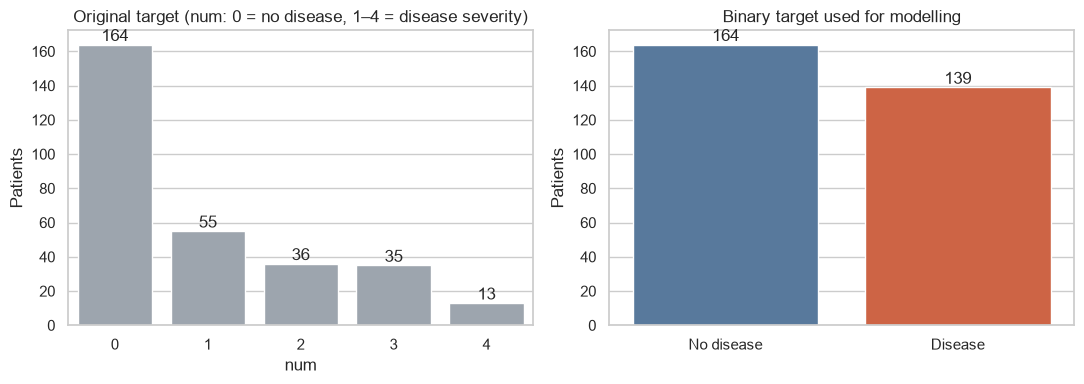

In [7]:
PALETTE = {"No disease": "#4C78A8", "Disease": "#E4572E"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.countplot(data=df, x="num", color="#9AA5B1", ax=axes[0])
axes[0].set_title("Original target (num: 0 = no disease, 1–4 = disease severity)")
axes[0].set_xlabel("num"); axes[0].set_ylabel("Patients")

sns.countplot(data=df, x="target_label", order=["No disease", "Disease"],
              hue="target_label", palette=PALETTE, legend=False, ax=axes[1])
axes[1].set_title("Binary target used for modelling")
axes[1].set_xlabel(""); axes[1].set_ylabel("Patients")

for ax in axes:
    for container in ax.containers:
        ax.bar_label(container)
plt.tight_layout()
savefig("eda_target_distribution.png")
plt.show()


## 2.5 Missing Values

In [8]:
missing_rows = df[df[["ca", "thal"]].isnull().any(axis=1)]
print(f"Rows with a missing value: {len(missing_rows)} of {len(df)} "
      f"({len(missing_rows) / len(df):.1%})")
display(missing_rows[["ca", "thal", "num", "target_label"]])

Rows with a missing value: 6 of 303 (2.0%)


,ca,thal,num,target_label
87,0.0,NaN,0,No disease
166,NaN,3.0,0,No disease
192,NaN,7.0,1,Disease
266,0.0,NaN,2,Disease
287,NaN,7.0,0,No disease
302,NaN,3.0,0,No disease


**Decision: keep these rows and impute inside the modelling pipeline.**

- Only a handful of rows are affected, and dropping rows would shrink an already small dataset.
- Imputation values (median for `ca`, most frequent for `thal`) will be learned from the **training split only**,
  so no information from held-out data leaks in.
- A real API request can also arrive with a gap, so the imputer must travel inside the saved model.

(The alternative, dropping the incomplete rows, is also defensible given how few there are.)

## 2.6 Numeric Features: Distribution and Class Separation

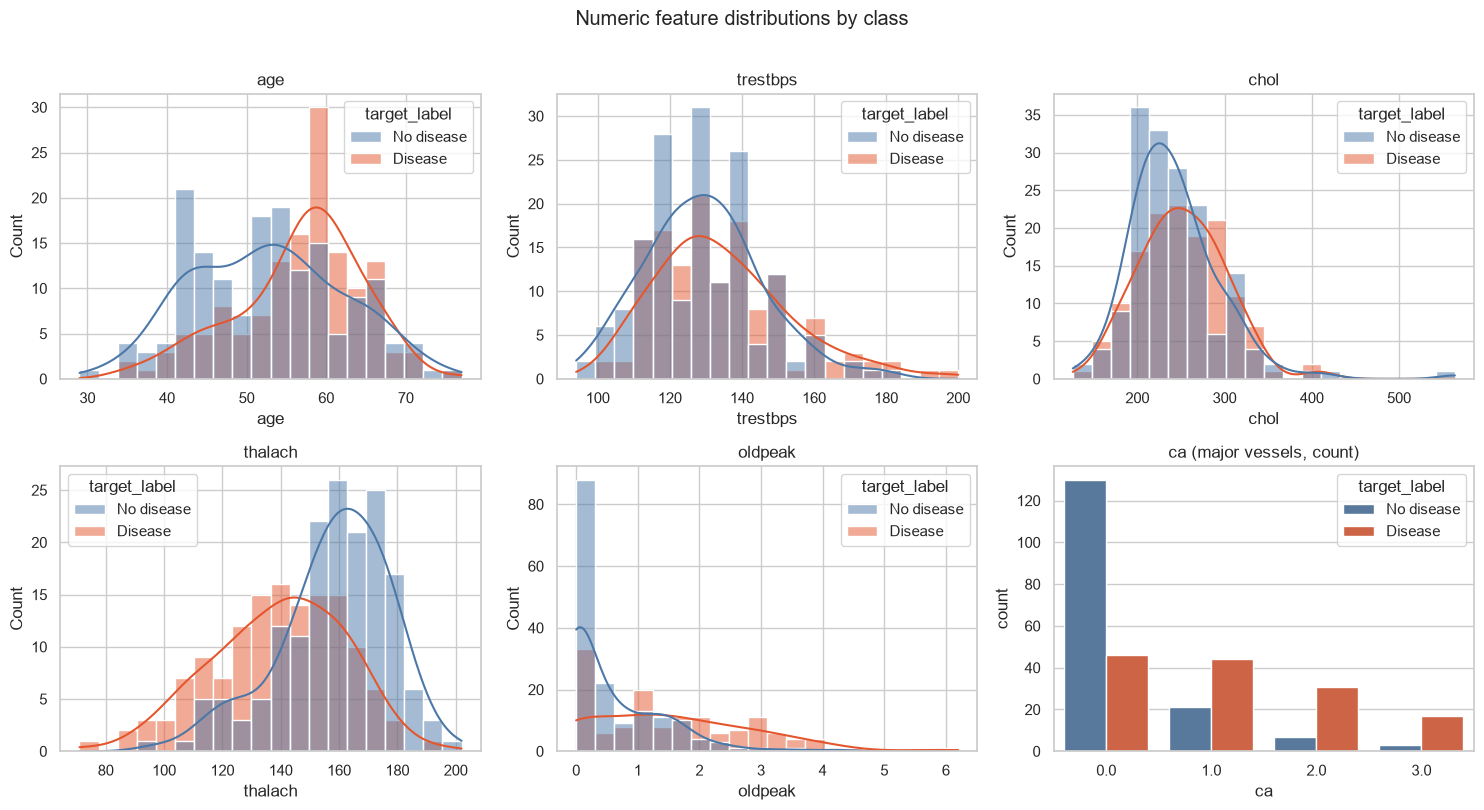

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, NUMERIC_CONT):
    sns.histplot(data=df, x=col, hue="target_label", palette=PALETTE,
                 bins=20, kde=True, alpha=0.5, ax=ax)
    ax.set_title(col)
sns.countplot(data=df, x="ca", hue="target_label", palette=PALETTE, ax=axes.flat[5])
axes.flat[5].set_title("ca (major vessels, count)")
plt.suptitle("Numeric feature distributions by class", y=1.01)
plt.tight_layout()
savefig("eda_numeric_distributions.png")
plt.show()

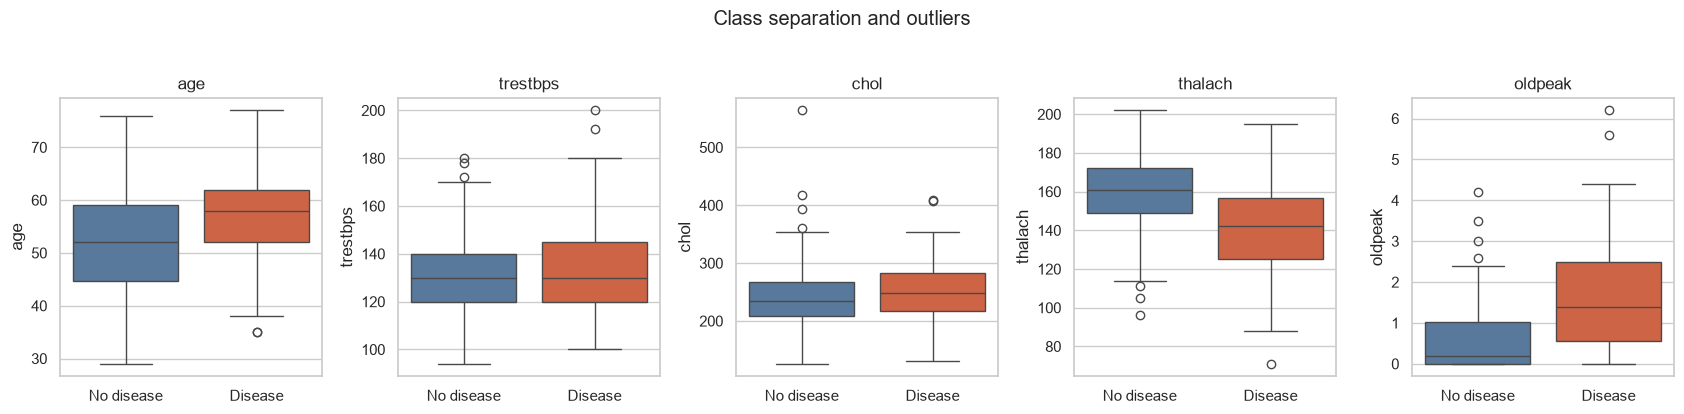

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(17, 4))
for ax, col in zip(axes, NUMERIC_CONT):
    sns.boxplot(data=df, x="target_label", y=col, order=["No disease", "Disease"],
                hue="target_label", palette=PALETTE, legend=False, ax=ax)
    ax.set_xlabel(""); ax.set_title(col)
plt.suptitle("Class separation and outliers", y=1.03)
plt.tight_layout()
savefig("eda_boxplots_outliers.png")
plt.show()

## 2.7 Categorical Features vs Target

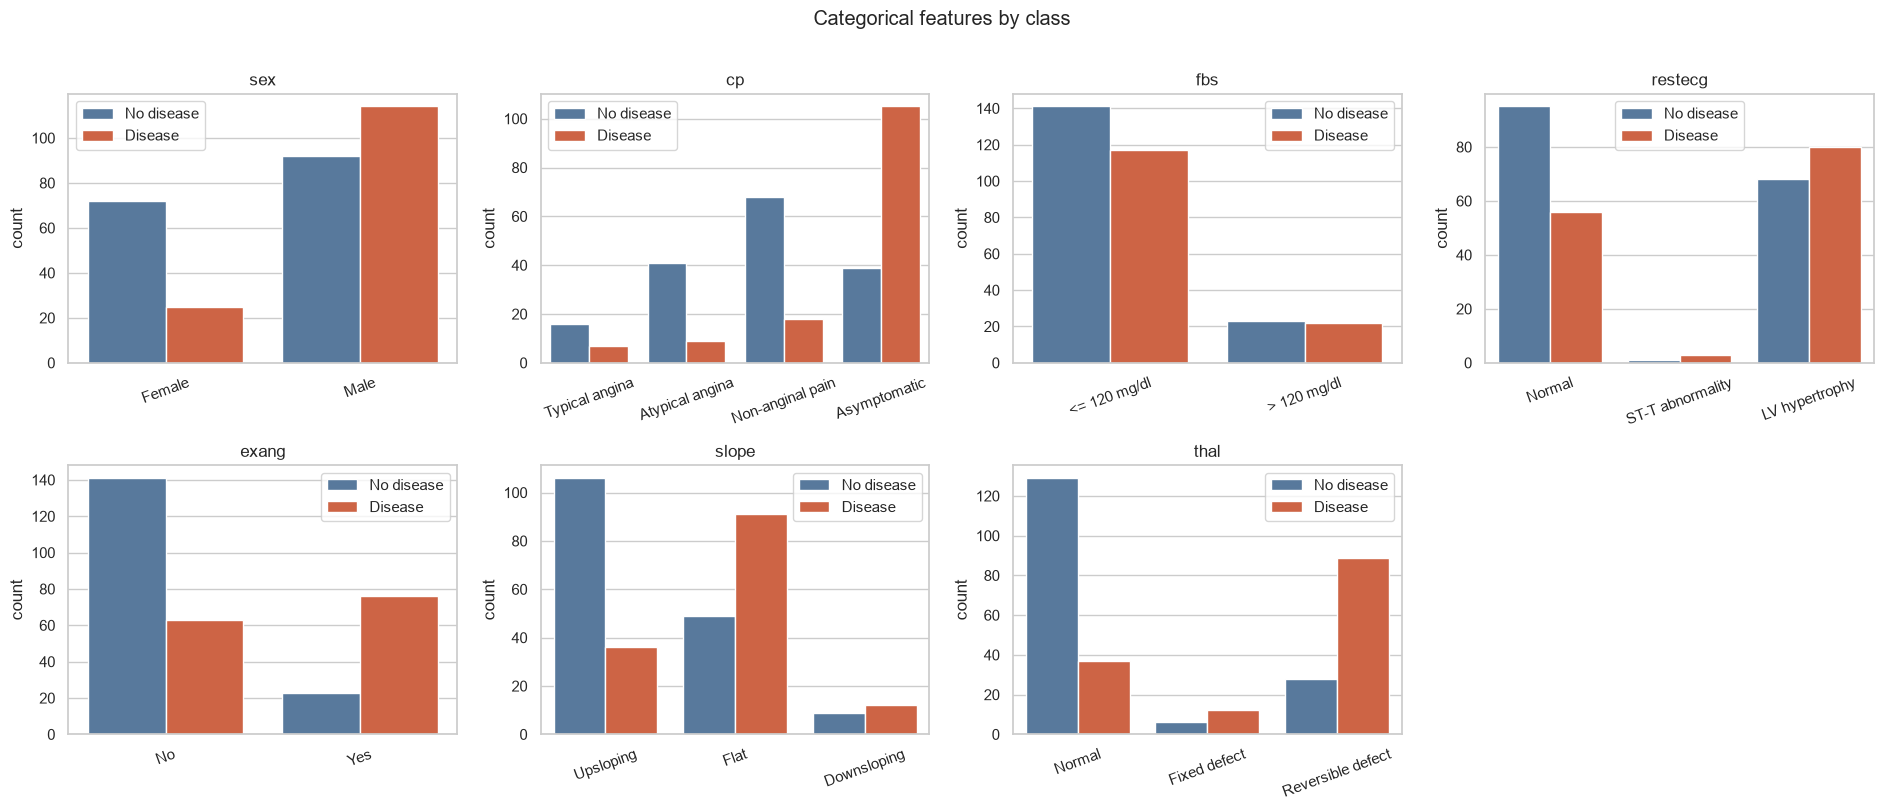

In [11]:
plot_df = df.copy()
for col, mapping in LABELS.items():
    plot_df[col] = plot_df[col].map(mapping)

fig, axes = plt.subplots(2, 4, figsize=(19, 8))
for ax, col in zip(axes.flat, CATEGORICAL):
    order = list(LABELS[col].values())
    sns.countplot(data=plot_df, x=col, order=order, hue="target_label",
                  hue_order=["No disease", "Disease"], palette=PALETTE, ax=ax)
    ax.set_title(col); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
    ax.get_legend().set_title("")
axes.flat[-1].axis("off")
plt.suptitle("Categorical features by class", y=1.01)
plt.tight_layout()
savefig("eda_categorical_vs_target.png")
plt.show()

## 2.8 Correlation Analysis

Pearson correlation is only meaningful for **numeric** features (and the binary target), so the heatmap
leaves out the coded categorical variables; those are covered by the category plots above.

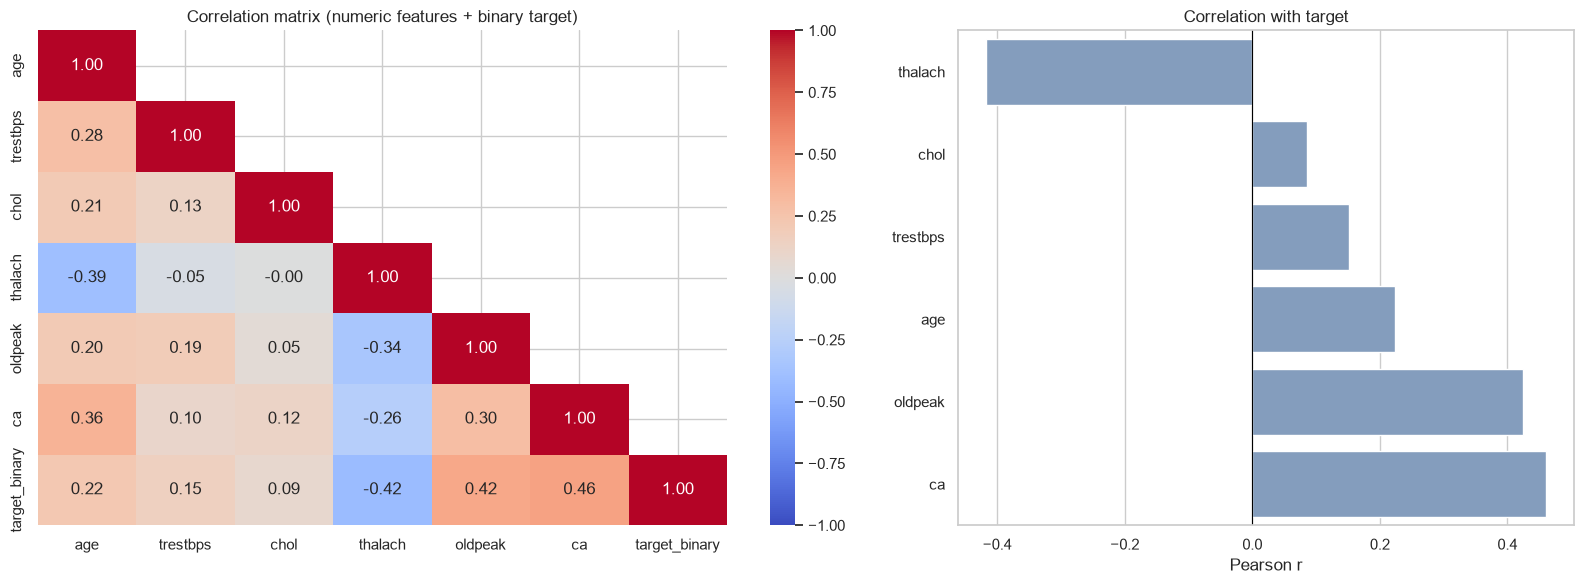

In [12]:
corr_cols = NUMERIC + ["target_binary"]
corr = df[corr_cols].corr()

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.4, 1]})

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Correlation matrix (numeric features + binary target)")

target_corr = corr["target_binary"].drop("target_binary").sort_values()
sns.barplot(x=target_corr.values, y=target_corr.index, color="#7A9CC6", ax=axes[1])
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Correlation with target")
axes[1].set_xlabel("Pearson r")
axes[1].set_ylabel("")  
plt.tight_layout()
savefig("eda_correlation.png")
plt.show()

## 2.9 Key Numbers for the Findings

In [13]:
print("Mean of numeric features by class:")
display(df.groupby("target_label")[NUMERIC].mean().round(2).T)

print("Skewness of continuous features:")
display(df[NUMERIC_CONT].skew().round(2).to_frame("skew").T)

q1, q3 = df[NUMERIC_CONT].quantile(0.25), df[NUMERIC_CONT].quantile(0.75)
iqr = q3 - q1
outliers = ((df[NUMERIC_CONT] < q1 - 1.5 * iqr) | (df[NUMERIC_CONT] > q3 + 1.5 * iqr)).sum()
print("Outliers by the 1.5 x IQR rule:")
display(outliers.to_frame("n_outliers").T)

print("Disease rate (% of patients) by category:")
for col in CATEGORICAL:
    rate = (df.groupby(col)["target_binary"].mean() * 100).round(1)
    counts = df.groupby(col).size()
    display(pd.DataFrame({"disease_rate_%": rate, "n": counts}).rename(index=LABELS[col]).T)

Mean of numeric features by class:


target_label,Disease,No disease
age,56.63,52.59
trestbps,134.57,129.25
chol,251.47,242.64
thalach,139.26,158.38
oldpeak,1.57,0.59
ca,1.14,0.27


Skewness of continuous features:


,age,trestbps,chol,thalach,oldpeak
skew,-0.21,0.71,1.14,-0.54,1.27


Outliers by the 1.5 x IQR rule:


...

fbs,<= 120 mg/dl,> 120 mg/dl
disease_rate_%,45.3,48.9
n,258.0,45.0


restecg,Normal,ST-T abnormality,LV hypertrophy
disease_rate_%,37.1,75.0,54.1
n,151.0,4.0,148.0


exang,No,Yes
disease_rate_%,30.9,76.8
n,204.0,99.0


slope,Upsloping,Flat,Downsloping
disease_rate_%,25.4,65.0,57.1
n,142.0,140.0,21.0


thal,Normal,Fixed defect,Reversible defect
disease_rate_%,22.3,66.7,76.1
n,166.0,18.0,117.0


## 2.10 Cleaned Dataset

Cleaning performed here: exact duplicates removed, original `num` converted to a binary `target`.
Missing values are **intentionally left** in the file and handled by the pipeline (see 2.5).

In [14]:
clean = df.drop_duplicates(subset=NUMERIC + CATEGORICAL + ["num"]).copy()
clean = clean.drop(columns=["num", "target_label"]).rename(columns={"target_binary": "target"})

CLEAN_PATH = DATA_DIR / "heart_disease_clean.csv"
clean.to_csv(CLEAN_PATH, index=False)
print("Saved:", CLEAN_PATH.relative_to(DATA_DIR.parent), clean.shape)
print("Remaining missing values:", int(clean.isnull().sum().sum()))

Saved: data\heart_disease_clean.csv (303, 14)
Remaining missing values: 6


## 2.11 Preprocessing Preview (fitted on the training split only)

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

X = clean[NUMERIC + CATEGORICAL]
y = clean["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), NUMERIC),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CATEGORICAL),
])

Xt_train = preprocess.fit_transform(X_train)      # learn imputers / scaler / categories on train only
Xt_test = preprocess.transform(X_test)

print("Train:", X_train.shape, "->", Xt_train.shape)
print("Test: ", X_test.shape, "->", Xt_test.shape)
print("NaNs left after preprocessing:", int(np.isnan(Xt_train).sum() + np.isnan(Xt_test).sum()))
print("Train class share:", y_train.mean().round(3), "| Test class share:", y_test.mean().round(3))
print("\nFirst encoded feature names:")
print(list(preprocess.get_feature_names_out()[:12]))

Train: (242, 13) -> (242, 25)
Test:  (61, 13) -> (61, 25)
NaNs left after preprocessing: 0
Train class share: 0.459 | Test class share: 0.459

First encoded feature names:
['num__age', 'num__trestbps', 'num__chol', 'num__thalach', 'num__oldpeak', 'num__ca', 'cat__sex_0.0', 'cat__sex_1.0', 'cat__cp_1.0', 'cat__cp_2.0', 'cat__cp_3.0', 'cat__cp_4.0']


## 2.12 EDA Findings and Conclusions

### Dataset overview
The Cleveland subset of the UCI Heart Disease data has 303 patients and 13 input features: 6 numeric (`age`, `trestbps`, `chol`, `thalach`, `oldpeak`, `ca`) and 7 categorical (`sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `thal`). The original target `num` has five levels (0-4); I collapsed it to a binary target (`num > 0` = heart disease present), which is the usual convention for this dataset.

### Data quality
- **Missing values:** `ca` has 4 (1.32%) and `thal` has 2 (0.66%), affecting 6 rows (2.0%). No duplicate records were found.
- **Decision:** I kept these rows and impute inside the modelling pipeline (median for `ca`, most frequent for `thal`), fitted on training data only. This avoids losing data and avoids leakage, and the imputer travels with the saved model, so API requests with gaps are handled too.
- **Outliers (1.5 × IQR):** `trestbps` 9, `chol` 5, `oldpeak` 5, `thalach` 1, `age` 0. I kept the outliers because they are plausible clinical readings. Tree models are insensitive to them; for the linear model, standard scaling is somewhat sensitive to them.

### Class balance
164 patients (54.1%) have no disease and 139 (45.9%) have disease. This is only mild imbalance, so no resampling is needed. I will still report precision, recall and ROC-AUC alongside accuracy, since missing a sick patient is the costlier error.

### Numeric features and class separation
- Patients with disease reach a **lower maximum heart rate** (`thalach`: 139.3 vs 158.4 on average).
- They show **more ST depression** (`oldpeak`: 1.57 vs 0.59) and **more blocked vessels** (`ca`: 1.14 vs 0.27).
- `age` separates the classes modestly (56.6 vs 52.6), while `chol` (251 vs 243) and `trestbps` (135 vs 129) overlap heavily and look weak on their own.
- `chol` (skew 1.14) and oldpeak (skew 1.27) are right-skewed. Features also sit on very different scales (e.g. chol ≈ 250 vs oldpeak ≈ 1), which motivates standard scaling for the linear model.

### Categorical features
- **Chest pain (`cp`):** disease is most common with *asymptomatic* chest pain (72.9%) and least common with *atypical angina* (18.0%). This is counter-intuitive, but it is a known pattern in this dataset.
- **`thal`:** reversible defect 76.1% and fixed defect 66.7%, versus 22.3% for normal. (Fixed defect has only 18 patients, so that rate is less reliable.)
- **`exang`:** 76.8% disease with exercise-induced angina vs 30.9% without.
- **`slope`:** flat 65.0% vs upsloping 25.4%. **`sex`:** male 55.3% vs female 25.8%.
- **`fbs`** barely separates the classes (48.9% vs 45.3%), so it is likely a weak predictor.
- `restecg` "ST-T abnormality" has only 4 patients, so its 75% rate should not be over-interpreted.

### Correlations
Among numeric features, the strongest correlations with the target are `ca` (r = 0.46), `thalach` (r = -0.42) and `oldpeak` (r = 0.42). The largest correlation between two predictors is `age` and `thalach` (r = -0.39), so multicollinearity is not a concern and all features are kept for modelling.

### Preprocessing implications
Numeric features are median-imputed and standardised; categorical features are most-frequent-imputed and one-hot encoded with `handle_unknown="ignore"`, giving 25 model features. A stratified 80/20 split gives 242 training and 61 test records. The preprocessing preview fits imputation, scaling, and one-hot encoding on the training split and applies the fitted transformer to the test split. This preview demonstrates the intended preprocessing logic; the final model training code should place the transformer inside each estimator pipeline so cross-validation refits preprocessing separately within each fold.
